**CS 4140 – Deep Learning · L09 · Generalization and regularization** &nbsp; [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Bolufe-Rohler/4140-deep-learning/blob/main/lectures/L09_generalization/L09_generalization.ipynb)

Run the first code cell before anything else. In Colab, *File → Save a copy in Drive* keeps your own changes.

In [ ]:
# ▶ Run this cell first. It gets the course code and this lecture's saved results and data,
#   in Google Colab or on your own computer.
LECTURE = "L09_generalization"
REPO = "https://github.com/Bolufe-Rohler/4140-deep-learning"
import os, sys, subprocess
root = os.path.abspath(os.path.join("..", ".."))
if not os.path.isfile(os.path.join(root, "cs4140_setup.py")):  # not inside the course repo (e.g. Colab)
    root = "/content/cs4140" if "google.colab" in sys.modules else os.path.abspath("cs4140")
    if not os.path.isdir(root):
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", REPO, root], check=True)
    os.chdir(os.path.join(root, "lectures", LECTURE))
sys.path.insert(0, root)
import cs4140_setup
cs4140_setup.fetch_assets(LECTURE)

# CS 4140 · Lecture 9 · Generalization: Learning, Not Memorizing

Companion notebook for the slides. Every number and every figure in the deck comes from this notebook.

| Experiment | Slide idea | Full run (2 CPU cores) |
|---|---|---|
| 1. Real vs shuffled labels | the hook: 100% training accuracy on random labels | ~3 min |
| 2. One intervention at a time | baseline, early stopping, weight decay, dropout, augmentation, all three, 5× more data | ~35 min |
| 3. The sealed envelope | the test set, opened once for the model we picked | <1 min |
| 4. Double descent | bigger can be better: random-feature networks of growing width | ~3 min |
| 5. Pictures | augmentation examples, weight histograms | seconds |

**Class mode** (`CLASS_MODE = True`, the default) loads the saved results in `results/` and only redraws the figures (about 15 s).
Set `CLASS_MODE = False` to re-run everything (about 40 minutes on a laptop CPU; no GPU needed).

**Setup.** Fashion-MNIST. We deliberately train on a small set, **2,000 images**, so overfitting shows up fast.
Validation: 5,000 other images from the training file. Test: the official 10,000 test images, used exactly once (Experiment 3).
Network: a small CNN (two 3×3 convolution layers with 16 and 32 filters, each followed by 2×2 max-pooling, then a 128-unit dense layer; 206,922 parameters).
Training: Adam, learning rate 0.001, minibatches of 64, 50 epochs, three seeds per setting.

In [1]:
CLASS_MODE = True          # False = re-run every experiment (~40 min on CPU)
DATA_DIR = './data'        # Fashion-MNIST is downloaded here on first use (~30 MB)

import json, math, time, os
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
import matplotlib
import matplotlib.pyplot as plt

torch.set_num_threads(max(1, os.cpu_count() or 1))
for d in ('results', 'figures', 'figures/slides', 'models'):
    os.makedirs(d, exist_ok=True)

matplotlib.rcParams.update({
    'font.family': 'serif', 'font.serif': ['Century Schoolbook', 'TeX Gyre Schola', 'DejaVu Serif'],
    'mathtext.fontset': 'dejavuserif', 'font.size': 16, 'axes.titlesize': 18, 'axes.labelsize': 17,
    'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 14, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.edgecolor': '#333333', 'axes.linewidth': 1.2, 'savefig.dpi': 200})
BLUE, RED, GOLD, TEAL, GRAY, NAVY = '#2B47C7', '#D62728', '#C98A00', '#2CA58D', '#6E6E6E', '#000080'
CLASSES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


def layered(name, size, rects, setup, layers):
    """Base figure (axes only) + one transparent PNG per layer with identical geometry (for click-by-click reveals)."""
    def new():
        fig = plt.figure(figsize=size); axs = [fig.add_axes(r) for r in rects]; setup(axs); return fig, axs
    fig, axs = new(); fig.savefig(f'figures/slides/{name}_base.png', facecolor='white'); plt.close(fig)
    for lname, draw in layers:
        fig, axs = new(); draw(axs)
        for ax in axs:
            ax.patch.set_alpha(0); [s.set_visible(False) for s in ax.spines.values()]
            ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(''); ax.set_ylabel(''); ax.set_title('')
            for t in list(ax.texts):
                if getattr(t, '_base', False): t.remove()
        fig.savefig(f'figures/slides/{name}_{lname}.png', transparent=True); plt.close(fig)
    fig, axs = new()
    for lname, draw in layers: draw(axs)
    fig.savefig(f'figures/{name}.png', facecolor='white'); plt.show(); plt.close(fig)


def save_json(o, p):
    with open(p, 'w') as f: json.dump(o, f)


def load_json(p):
    with open(p) as f: return json.load(f)


def need(p):
    return (not CLASS_MODE) or (not os.path.exists(p))

## Data, splits and the CNN

In [2]:
tr = torchvision.datasets.FashionMNIST(DATA_DIR, train=True, download=True)
te = torchvision.datasets.FashionMNIST(DATA_DIR, train=False, download=True)
X = ((tr.data.float() / 255. - 0.2860) / 0.3530).unsqueeze(1); y = tr.targets.clone()
Xtest = ((te.data.float() / 255. - 0.2860) / 0.3530).unsqueeze(1); ytest = te.targets.clone()   # sealed until Experiment 3

perm = torch.randperm(60000, generator=torch.Generator().manual_seed(0))
pool, val_idx = perm[:50000], perm[50000:55000]
Xv, yv = X[val_idx], y[val_idx]
N_SMALL, N_BIG = 2000, 10000
print('small training set:', N_SMALL, '| bigger set:', N_BIG, '| validation:', len(val_idx), '| test (sealed):', len(Xtest))


class CNN(nn.Module):
    def __init__(self, p_drop=0.0):
        super().__init__()
        self.features = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                      nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten())
        self.head = nn.Sequential(nn.Dropout(p_drop), nn.Linear(32 * 7 * 7, 128), nn.ReLU(), nn.Dropout(p_drop), nn.Linear(128, 10))

    def forward(self, x):
        return self.head(self.features(x))


def augment(x, g):
    """Random horizontal flip + random shift of up to 2 pixels (pad 2, random 28x28 crop)."""
    n = x.shape[0]
    flip = torch.rand(n, generator=g) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    pad = F.pad(x, (2, 2, 2, 2), value=float(x.min()))
    dx = torch.randint(0, 5, (n,), generator=g); dy = torch.randint(0, 5, (n,), generator=g)
    out = torch.empty_like(x)
    for i in range(5):
        for j in range(5):
            m = (dx == i) & (dy == j)
            if m.any(): out[m] = pad[m, :, j:j + 28, i:i + 28]
    return out


@torch.no_grad()
def evaluate(m, Xe, ye, bs=2500):
    m.eval(); L, c = 0., 0
    for i in range(0, len(Xe), bs):
        o = m(Xe[i:i + bs]); L += F.cross_entropy(o, ye[i:i + bs], reduction='sum').item(); c += (o.argmax(1) == ye[i:i + bs]).sum().item()
    m.train(); return L / len(Xe), c / len(Xe)


def fit(n=N_SMALL, epochs=50, wd=0.0, p_drop=0.0, aug=False, seed=0, labels=None, save=None):
    Xt = X[pool[:n]]; yt = y[pool[:n]] if labels is None else labels
    torch.manual_seed(seed); m = CNN(p_drop)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3, weight_decay=wd)   # weight_decay = L2 penalty λ
    g = torch.Generator().manual_seed(seed + 7); hist = []
    for ep in range(epochs):
        p = torch.randperm(n, generator=g)
        for i in range(0, n, 64):
            idx = p[i:i + 64]; xb = Xt[idx]
            if aug: xb = augment(xb, g)
            loss = F.cross_entropy(m(xb), yt[idx]); opt.zero_grad(); loss.backward(); opt.step()
        hist.append(evaluate(m, Xt, yt) + evaluate(m, Xv, yv))      # (train loss, train acc, val loss, val acc)
    if save: torch.save(m.state_dict(), save)
    return m, hist


print('parameters:', sum(p.numel() for p in CNN().parameters()))

small training set: 2000 | bigger set: 10000 | validation: 5000 | test (sealed): 10000
parameters: 206922


## Experiment 1 · 100% training accuracy. Ship it?
Two runs of the same CNN on the same 2,000 images, 60 epochs. Run B's labels were shuffled at random
(only 10.5% of them still match the real class), so there is nothing to learn, only something to memorize.

real      train acc 100.0% (≥99.9% from epoch 39)   val acc 83.7%
shuffled  train acc 100.0% (≥99.9% from epoch 43)   val acc 9.5%
fraction of shuffled labels that are still correct: 0.105


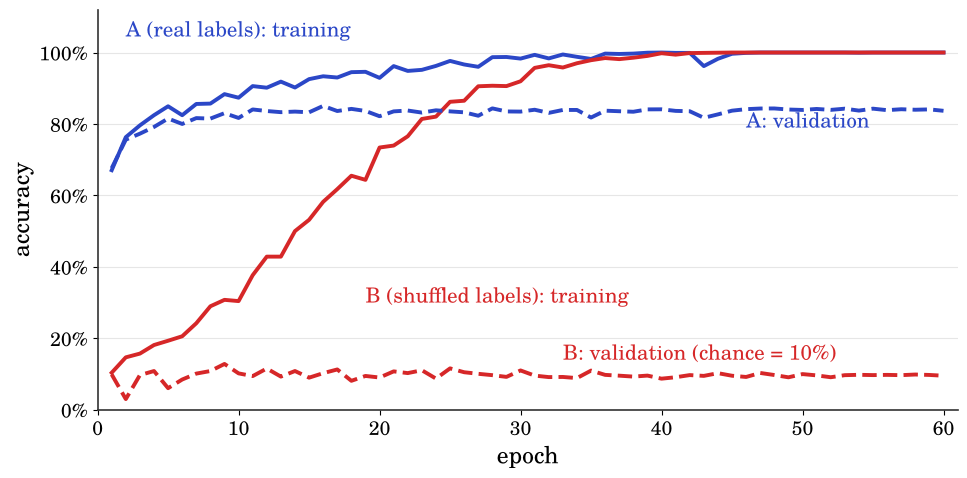

In [3]:
P1 = 'results/e1_real_vs_shuffled.json'
y_shuf = y[pool[:N_SMALL]][torch.randperm(N_SMALL, generator=torch.Generator().manual_seed(5))]
if need(P1):
    _, h_real = fit(epochs=60)
    _, h_shuf = fit(epochs=60, labels=y_shuf)
    save_json({'real': h_real, 'shuffled': h_shuf, 'match': float((y_shuf == y[pool[:N_SMALL]]).float().mean())}, P1)
e1 = load_json(P1)
for k in ('real', 'shuffled'):
    H = np.array(e1[k]); first100 = int(np.argmax(H[:, 1] >= 0.999)) + 1 if (H[:, 1] >= 0.999).any() else None
    print(f'{k:9s} train acc {H[-1,1]*100:.1f}% (≥99.9% from epoch {first100})   val acc {H[-1,3]*100:.1f}%')
print('fraction of shuffled labels that are still correct:', round(e1['match'], 3))


def setup_hook(axs):
    ax = axs[0]; ax.set_xlim(0, 61); ax.set_ylim(0, 1.12); ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0]); ax.set_xlabel('epoch'); ax.set_ylabel('accuracy')
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0)); ax.grid(axis='y', color='#E6E6E6')


def hook_layer(k, col, which, color, ls, label, xy):
    def draw(axs):
        H = np.array(e1[k]); e = np.arange(1, len(H) + 1)
        axs[0].plot(e, H[:, col], ls, color=color, lw=2.8); axs[0].text(*xy, label, color=color, fontsize=15)
    return draw


layered('l09_hook', (10, 5.0), [[0.1, 0.15, 0.86, 0.8]], setup_hook,
        [('train_real', hook_layer('real', 1, 'train', BLUE, '-', 'A (real labels): training', (2, 1.045))),
         ('train_shuf', hook_layer('shuffled', 1, 'train', RED, '-', 'B (shuffled labels): training', (19, 0.3))),
         ('val_real', hook_layer('real', 3, 'val', BLUE, '--', 'A: validation', (46, 0.79))),
         ('val_shuf', hook_layer('shuffled', 3, 'val', RED, '--', 'B: validation (chance = 10%)', (33, 0.14)))])

## Experiment 2 · One intervention at a time
Every row changes exactly one thing relative to the baseline (except "all three"). Three seeds each.
Early stopping needs no extra run: it picks, from the baseline's own history, the epoch with the best validation accuracy.

In [4]:
P2 = 'results/e2_interventions.json'
CONFIGS = {'baseline': {}, 'weight decay': {'wd': 5e-3}, 'dropout': {'p_drop': 0.5}, 'augmentation': {'aug': True},
           'all three': {'wd': 5e-3, 'p_drop': 0.5, 'aug': True}, '5× more data': {'n': N_BIG}}
complete = lambda p: os.path.exists(p) and all(len(load_json(p).get(k, [])) == 3 for k in CONFIGS)
if need(P2) or not complete(P2):          # an interrupted run resumes where it stopped (class mode)
    e2 = load_json(P2) if (CLASS_MODE and os.path.exists(P2)) else {}
    for name, kw in CONFIGS.items():
        runs = e2.get(name, [])
        for s in range(len(runs), 3):
            t0 = time.time()
            _, h = fit(seed=s, save=f"models/{name.replace(' ', '_').replace('×', 'x')}_seed{s}.pt", **kw)
            runs.append(h); e2[name] = runs; save_json(e2, P2)
            print(f'{name:14s} seed {s}: val acc {h[-1][3]*100:.1f}%  ({time.time()-t0:.0f}s)', flush=True)
e2 = load_json(P2)


def summarize(hists, pick='last'):
    rows = []
    for h in hists:
        H = np.array(h); i = len(H) - 1 if pick == 'last' else int(np.argmax(H[:, 3]))
        rows.append((H[i, 1], H[i, 3], H[i, 2], i + 1))
    R = np.array(rows); return dict(train=R[:, 0].mean(), val=R[:, 1].mean(), val_loss=R[:, 2].mean(), epoch=R[:, 3].mean(),
                                     val_min=R[:, 1].min(), val_max=R[:, 1].max(), gap=(R[:, 0] - R[:, 1]).mean())


score = {'baseline': summarize(e2['baseline']), 'early stopping': summarize(e2['baseline'], pick='best')}
for name in list(CONFIGS)[1:]:
    score[name] = summarize(e2[name])
print(f"{'':16s}{'train':>8s}{'val':>8s}{'gap':>8s}{'val loss':>10s}{'epoch':>7s}")
for k, v in score.items():
    print(f"{k:16s}{v['train']*100:7.1f}%{v['val']*100:7.1f}%{v['gap']*100:7.1f}%{v['val_loss']:10.3f}{v['epoch']:7.0f}   (val {v['val_min']*100:.1f}–{v['val_max']*100:.1f}%)")
save_json(score, 'results/e2_scoreboard.json')

                   train     val     gap  val loss  epoch
baseline           99.8%   84.1%   15.7%     0.782     50   (val 83.8–84.7%)
early stopping     93.7%   85.1%    8.6%     0.440     16   (val 84.9–85.3%)
weight decay       97.4%   83.7%   13.7%     0.503     50   (val 82.6–84.4%)
dropout            96.6%   85.6%   11.0%     0.443     50   (val 85.5–85.7%)
augmentation       92.4%   85.0%    7.4%     0.439     50   (val 84.6–85.3%)
all three          83.7%   81.2%    2.5%     0.493     50   (val 81.0–81.5%)
5× more data      100.0%   88.7%   11.3%     0.810     50   (val 88.3–88.9%)


### Reading the gap: the baseline's learning curves (seed 0)

best val acc at epoch 16 (85.1%) | lowest val loss at epoch 11 (0.434) | final: train acc 100.0%, val acc 83.9%, val loss 0.776


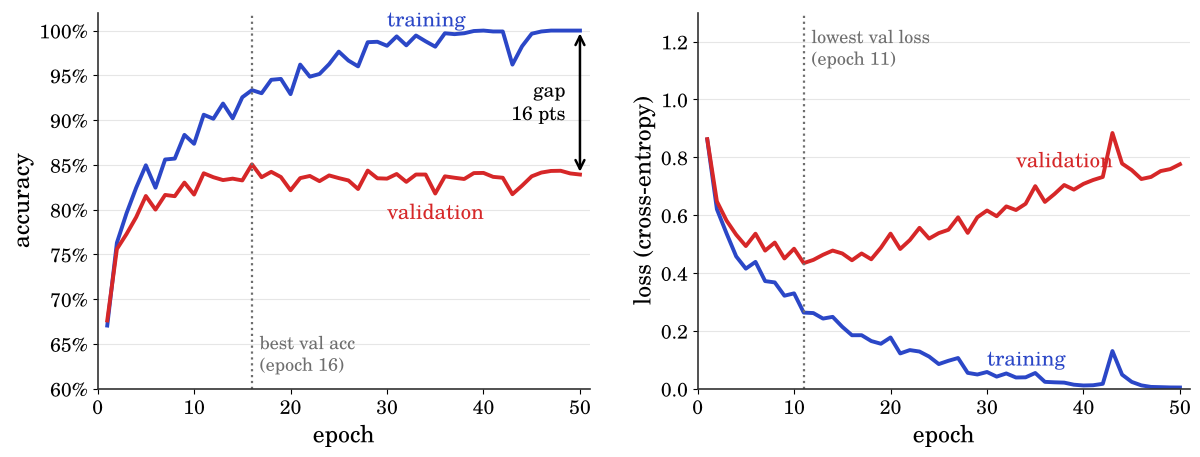

In [5]:
Hb = np.array(e2['baseline'][0]); eb = np.arange(1, len(Hb) + 1)
best_acc_ep = int(np.argmax(Hb[:, 3])) + 1; best_loss_ep = int(np.argmin(Hb[:, 2])) + 1
print('best val acc at epoch', best_acc_ep, f'({Hb[best_acc_ep-1,3]*100:.1f}%)', '| lowest val loss at epoch', best_loss_ep, f'({Hb[best_loss_ep-1,2]:.3f})',
      f'| final: train acc {Hb[-1,1]*100:.1f}%, val acc {Hb[-1,3]*100:.1f}%, val loss {Hb[-1,2]:.3f}')


def setup_gap(axs):
    a, b = axs
    a.set_xlim(0, 51); a.set_ylim(0.6, 1.02); a.set_xlabel('epoch'); a.set_ylabel('accuracy'); a.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))
    b.set_xlim(0, 51); b.set_ylim(0, 1.3); b.set_xlabel('epoch'); b.set_ylabel('loss (cross-entropy)')
    for ax in axs: ax.grid(axis='y', color='#E6E6E6')


def gap_train(axs):
    axs[0].plot(eb, Hb[:, 1], color=BLUE, lw=2.8); axs[0].text(30, 1.0, 'training', color=BLUE, fontsize=15, va='bottom')
    axs[1].plot(eb, Hb[:, 0], color=BLUE, lw=2.8); axs[1].text(30, 0.08, 'training', color=BLUE, fontsize=15)


def gap_val(axs):
    axs[0].plot(eb, Hb[:, 3], color=RED, lw=2.8); axs[0].text(30, Hb[29, 3] - 0.045, 'validation', color=RED, fontsize=15)
    axs[1].plot(eb, Hb[:, 2], color=RED, lw=2.8); axs[1].text(33, Hb[35, 2] + 0.12, 'validation', color=RED, fontsize=15)


def gap_marks(axs):
    a, b = axs
    a.annotate('', xy=(50, Hb[-1, 3]), xytext=(50, Hb[-1, 1]), arrowprops=dict(arrowstyle='<->', color='black', lw=1.8))
    a.text(48.5, (Hb[-1, 3] + Hb[-1, 1]) / 2, f'gap\n{(Hb[-1,1]-Hb[-1,3])*100:.0f} pts', ha='right', va='center', fontsize=14)
    a.axvline(best_acc_ep, color=GRAY, ls=':', lw=1.6); a.text(best_acc_ep + 0.8, 0.62, f'best val acc\n(epoch {best_acc_ep})', color=GRAY, fontsize=13)
    b.axvline(best_loss_ep, color=GRAY, ls=':', lw=1.6); b.text(best_loss_ep + 0.8, 1.12, f'lowest val loss\n(epoch {best_loss_ep})', color=GRAY, fontsize=13)


layered('l09_gap', (12, 4.7), [[0.07, 0.16, 0.41, 0.8], [0.57, 0.16, 0.41, 0.8]], setup_gap,
        [('train', gap_train), ('val', gap_val), ('marks', gap_marks)])

## Experiment 3 · The sealed envelope
We pick a setting **using validation accuracy only** (among the 2,000-image settings), then open the test set once.

In [6]:
P3 = 'results/e3_test_once.json'
cands = {k: v for k, v in score.items() if k in ('baseline', 'weight decay', 'dropout', 'augmentation', 'all three')}
chosen = max(cands, key=lambda k: cands[k]['val'])
if need(P3):
    kw = CONFIGS.get(chosen, {})
    accs = []
    for s in range(3):
        m = CNN(kw.get('p_drop', 0.0)); m.load_state_dict(torch.load(f"models/{chosen.replace(' ', '_')}_seed{s}.pt")); accs.append(evaluate(m, Xtest, ytest)[1])
    save_json({'chosen': chosen, 'val': cands[chosen]['val'], 'test_per_seed': accs, 'test': float(np.mean(accs))}, P3)
e3 = load_json(P3)
print(f"chosen by validation: {e3['chosen']}  (val {e3['val']*100:.1f}%)  →  test accuracy, opened once: {e3['test']*100:.1f}%  per seed {np.round(np.array(e3['test_per_seed'])*100,1)}")

chosen by validation: dropout  (val 85.6%)  →  test accuracy, opened once: 85.4%  per seed [85.3 85.3 85.4]


## Experiment 4 · Double descent: bigger can be better
A one-hidden-layer network whose hidden layer is **frozen at random** (random ReLU features); only the output layer is trained,
with the minimum-norm least-squares solution. 1,000 training images, validation on the 5,000 validation images, 3 seeds.
Classic U-curve thinking predicts that test error keeps rising once the model can fit the training set exactly (p ≥ n).
Instead, the error peaks right at p = n = 1,000 and then falls again.

best before the peak: p=200 val err 23.7% | peak: p=1000 val err 87.9% | widest: p=20000 val err 20.8%


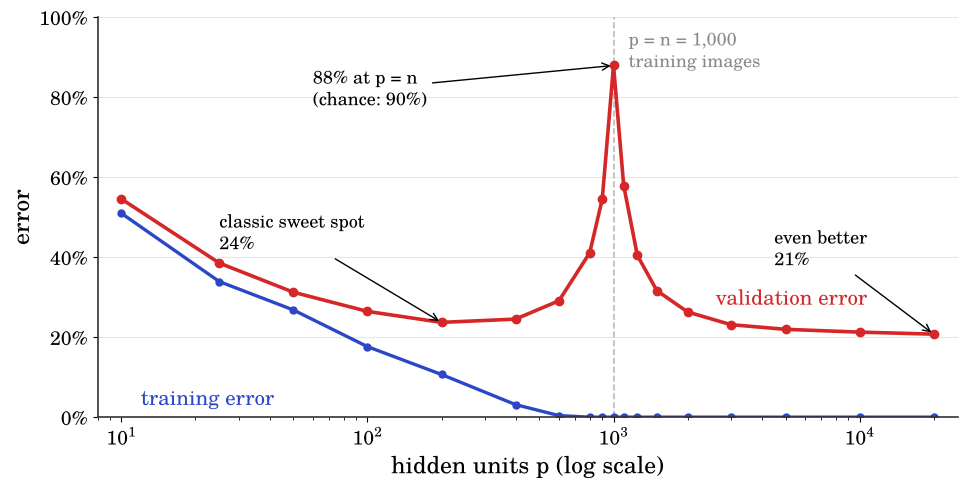

In [7]:
P4 = 'results/e4_double_descent.json'
PS = [10, 25, 50, 100, 200, 400, 600, 800, 900, 1000, 1100, 1250, 1500, 2000, 3000, 5000, 10000, 20000]
if need(P4):
    n_dd = 1000
    Xa = X[pool[:n_dd]].reshape(n_dd, -1).numpy().astype(np.float32); ya = y[pool[:n_dd]].numpy()
    Xb = Xv.reshape(len(Xv), -1).numpy().astype(np.float32); yb = yv.numpy()
    Y = np.eye(10, dtype=np.float32)[ya]
    res = {'p': PS, 'val_err': [], 'train_err': []}
    for p in PS:
        ve, tr_ = [], []
        for s in range(3):
            W = np.random.default_rng(s).standard_normal((784, p)).astype(np.float32) / np.sqrt(784)
            Fa = np.maximum(Xa @ W, 0)
            beta = np.linalg.lstsq(Fa, Y, rcond=None)[0]
            tr_.append(float((np.argmax(Fa @ beta, 1) != ya).mean()))
            pred = np.concatenate([np.argmax(np.maximum(Xb[i:i + 1000] @ W, 0) @ beta, 1) for i in range(0, len(Xb), 1000)])
            ve.append(float((pred != yb).mean()))
        res['val_err'].append(ve); res['train_err'].append(tr_); print(f'p={p:6d}  train err {np.mean(tr_)*100:5.1f}%  val err {np.mean(ve)*100:5.1f}%', flush=True)
    save_json(res, P4)
e4 = load_json(P4)
VE = np.array(e4['val_err']).mean(1); TE = np.array(e4['train_err']).mean(1)
i_min_small = int(np.argmin(VE[:PS.index(1000)])); i_peak = int(np.argmax(VE))
print(f"best before the peak: p={PS[i_min_small]} val err {VE[i_min_small]*100:.1f}% | peak: p={PS[i_peak]} val err {VE[i_peak]*100:.1f}% | widest: p={PS[-1]} val err {VE[-1]*100:.1f}%")


def setup_dd(axs):
    ax = axs[0]; ax.set_xscale('log'); ax.set_xlim(8, 25000); ax.set_ylim(0, 1.0); ax.set_xlabel('hidden units p (log scale)')
    ax.set_ylabel('error'); ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0)); ax.grid(axis='y', color='#E6E6E6')
    ax.axvline(1000, color='#BBBBBB', ls='--', lw=1.2)
    t = ax.text(1150, 0.97, 'p = n = 1,000\ntraining images', color='#888888', fontsize=13, va='top'); t._base = True


def dd_train(axs):
    axs[0].plot(PS, TE, 'o-', color=BLUE, lw=2.4, ms=5); axs[0].text(12, 0.02, 'training error', color=BLUE, fontsize=15, va='bottom')


def dd_val(axs):
    axs[0].plot(PS, VE, 'o-', color=RED, lw=2.6, ms=6); axs[0].text(2600, VE[PS.index(3000)] + 0.05, 'validation error', color=RED, fontsize=15)


def dd_marks(axs):
    ax = axs[0]
    ax.annotate(f'classic sweet spot\n{VE[i_min_small]*100:.0f}%', xy=(PS[i_min_small], VE[i_min_small]), xytext=(25, 0.42), fontsize=13, color='black',
                arrowprops=dict(arrowstyle='->', color='black'))
    ax.annotate(f'even better\n{VE[-1]*100:.0f}%', xy=(PS[-1], VE[-1]), xytext=(4500, 0.38), fontsize=13, color='black', arrowprops=dict(arrowstyle='->', color='black'))
    ax.annotate(f'{VE[i_peak]*100:.0f}% at p = n\n(chance: 90%)', xy=(PS[i_peak], VE[i_peak]), xytext=(60, 0.78), fontsize=13, color='black', arrowprops=dict(arrowstyle='->', color='black'))


layered('l09_double_descent', (10, 5.0), [[0.1, 0.15, 0.86, 0.8]], setup_dd, [('train', dd_train), ('val', dd_val), ('marks', dd_marks)])

## Experiment 5 · Pictures for the slides: augmentation and weight decay

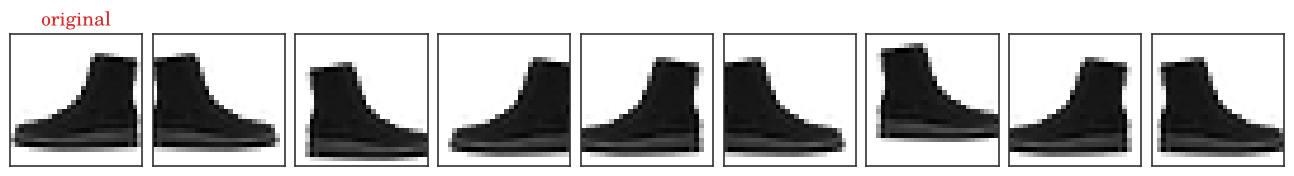

dense-layer weights: baseline std 0.0360, max |w| 0.325 | weight decay std 0.0136, max |w| 0.152
norm of all weights: baseline 18.1 | weight decay 8.7


/tmp/ipykernel_1019/609043291.py:20: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  norm = lambda m: float(sum((p ** 2).sum() for n_, p in m.named_parameters() if 'weight' in n_) ** 0.5)


dropout model on validation: model.eval() 85.6%  |  forgot model.eval() (dropout still on) 82.9%


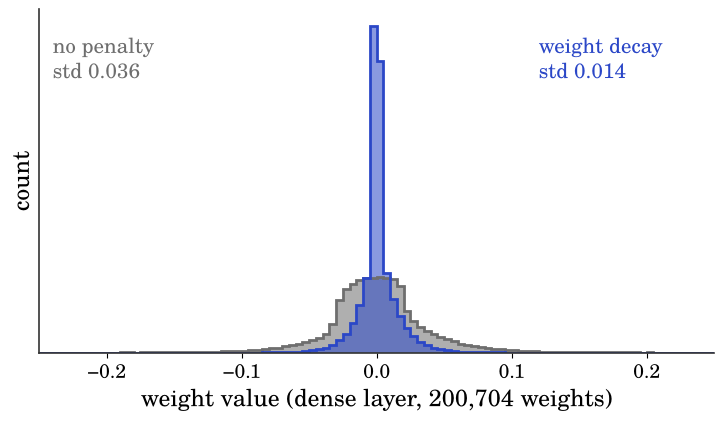

In [8]:
g = torch.Generator().manual_seed(3)
k_boot = int((y[pool[:N_SMALL]] == 9).nonzero()[0]); img0 = X[pool[:N_SMALL]][k_boot:k_boot + 1]
show = lambda t: (t.squeeze().numpy() * 0.3530 + 0.2860)
fig, axs = plt.subplots(1, 9, figsize=(13, 1.9))
axs[0].imshow(show(img0), cmap='gray_r', vmin=0, vmax=1); axs[0].set_title('original', fontsize=14, color=RED)
for a in axs[1:]: a.imshow(show(augment(img0, g)), cmap='gray_r', vmin=0, vmax=1)
for a in axs: a.set_xticks([]); a.set_yticks([]); [s.set_visible(True) for s in a.spines.values()]
fig.subplots_adjust(left=0.01, right=0.99, top=0.8, bottom=0.02, wspace=0.08)
fig.savefig('figures/slides/l09_aug_grid.png', facecolor='white'); plt.show(); plt.close(fig)

# three single images (original, flipped, shifted) for the original augmentation slide
for nm, t_ in [('orig', img0), ('flip', img0.flip(3)), ('shift', F.pad(img0, (3, 0, 0, 3), value=float(img0.min()))[:, :, 3:, :28])]:
    fig = plt.figure(figsize=(2.2, 2.2)); ax = fig.add_axes([0, 0, 1, 1]); ax.imshow(show(t_), cmap='gray_r', vmin=0, vmax=1); ax.axis('off')
    fig.savefig(f'figures/slides/l09_boot_{nm}.png', facecolor='white'); plt.close(fig)

# weight histograms: first dense layer, baseline vs weight decay (seed 0)
mb = CNN(); mb.load_state_dict(torch.load('models/baseline_seed0.pt'))
mw = CNN(); mw.load_state_dict(torch.load('models/weight_decay_seed0.pt'))
wb = mb.head[1].weight.detach().flatten().numpy(); ww = mw.head[1].weight.detach().flatten().numpy()
norm = lambda m: float(sum((p ** 2).sum() for n_, p in m.named_parameters() if 'weight' in n_) ** 0.5)
print(f'dense-layer weights: baseline std {wb.std():.4f}, max |w| {np.abs(wb).max():.3f} | weight decay std {ww.std():.4f}, max |w| {np.abs(ww).max():.3f}')
print(f'norm of all weights: baseline {norm(mb):.1f} | weight decay {norm(mw):.1f}')
# train mode vs eval mode: the dropout model evaluated with dropout still switched on (a classic bug)
md = CNN(0.5); md.load_state_dict(torch.load('models/dropout_seed0.pt'))
acc_eval = evaluate(md, Xv, yv)[1]
torch.manual_seed(0); md.train()
with torch.no_grad():
    acc_train_mode = float((md(Xv).argmax(1) == yv).float().mean())
print(f'dropout model on validation: model.eval() {acc_eval*100:.1f}%  |  forgot model.eval() (dropout still on) {acc_train_mode*100:.1f}%')
save_json({'baseline_std': float(wb.std()), 'wd_std': float(ww.std()), 'baseline_norm': norm(mb), 'wd_norm': norm(mw),
           'dropout_eval_mode': acc_eval, 'dropout_train_mode': acc_train_mode}, 'results/e5_weights.json')
bins = np.linspace(-0.25, 0.25, 101)


def setup_w(axs):
    ax = axs[0]; ax.set_xlim(-0.25, 0.25); ax.set_xlabel('weight value (dense layer, 200,704 weights)'); ax.set_ylabel('count'); ax.set_yticks([])


def w_layer(w, color, label, xy):
    def draw(axs):
        axs[0].hist(w, bins=bins, color=color, alpha=0.55, histtype='stepfilled'); axs[0].hist(w, bins=bins, color=color, histtype='step', lw=2)
        axs[0].text(*xy, label, color=color, fontsize=15, transform=axs[0].transAxes)
    return draw


layered('l09_weights', (7.5, 4.4), [[0.06, 0.17, 0.9, 0.78]], setup_w,
        [('base', w_layer(wb, GRAY, f'no penalty\nstd {wb.std():.3f}', (0.02, 0.8))), ('wd', w_layer(ww, BLUE, f'weight decay\nstd {ww.std():.3f}', (0.74, 0.8)))])

## All the numbers used on the slides

In [9]:
summary = {'hook': {k: {'train_acc': e1[k][-1][1], 'val_acc': e1[k][-1][3]} for k in ('real', 'shuffled')},
           'scoreboard': score, 'test_once': e3,
           'double_descent': {'best_small_p': PS[i_min_small], 'best_small_err': float(VE[i_min_small]), 'peak_p': PS[i_peak],
                              'peak_err': float(VE[i_peak]), 'widest_err': float(VE[-1])},
           'weights': load_json('results/e5_weights.json')}
save_json(summary, 'results/summary.json'); print(json.dumps(summary, indent=1))

{
 "hook": {
  "real": {
   "train_acc": 1.0,
   "val_acc": 0.8368
  },
  "shuffled": {
   "train_acc": 1.0,
   "val_acc": 0.095
  }
 },
 "scoreboard": {
  "baseline": {
   "train": 0.9981666666666666,
   "val": 0.8414666666666667,
   "val_loss": 0.7817793701171875,
   "epoch": 50.0,
   "val_min": 0.8382,
   "val_max": 0.847,
   "gap": 0.15670000000000006
  },
  "early stopping": {
   "train": 0.9369999999999999,
   "val": 0.8509333333333333,
   "val_loss": 0.43984374186197917,
   "epoch": 16.333333333333332,
   "val_min": 0.849,
   "val_max": 0.8532,
   "gap": 0.0860666666666667
  },
  "weight decay": {
   "train": 0.9738333333333333,
   "val": 0.8367333333333334,
   "val_loss": 0.5032586100260418,
   "epoch": 50.0,
   "val_min": 0.826,
   "val_max": 0.8438,
   "gap": 0.1371
  },
  "dropout": {
   "train": 0.9656666666666666,
   "val": 0.8559333333333333,
   "val_loss": 0.44294809570312493,
   "epoch": 50.0,
   "val_min": 0.8546,
   "val_max": 0.8574,
   "gap": 0.10973333333333328
  }